In [1]:
# Load & shape
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)

base = '../data/raw/'
train = pd.read_csv(base+'train.csv', parse_dates=['date'])
stores = pd.read_csv(base+'stores.csv')
oil = pd.read_csv(base+'oil.csv', parse_dates=['date'])
holidays = pd.read_csv(base+'holidays_events.csv', parse_dates=['date'])
transactions = pd.read_csv(base+'transactions.csv', parse_dates=['date'])

for name, df in [('train',train),('stores',stores),('oil',oil),('holidays',holidays),('transactions',transactions)]:
    print(f"{name}: {df.shape}")

train: (3000888, 6)
stores: (54, 5)
oil: (1218, 2)
holidays: (350, 6)
transactions: (83488, 3)


In [2]:
# Date range & gaps
print("train dates:", train.date.min(), "→", train.date.max())
full = pd.date_range(train.date.min(), train.date.max(), freq='D')
missing = full.difference(train.date.unique())
print("missing dates:", len(missing))
print("unique stores:", train.store_nbr.nunique())
print("unique families:", train.family.nunique())

train dates: 2013-01-01 00:00:00 → 2017-08-15 00:00:00
missing dates: 4
unique stores: 54
unique families: 33


In [3]:
# Sales distribution
print(train.sales.describe())
print("\n% zero sales:", (train.sales==0).mean()*100)

count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64

% zero sales: 31.29506999261552


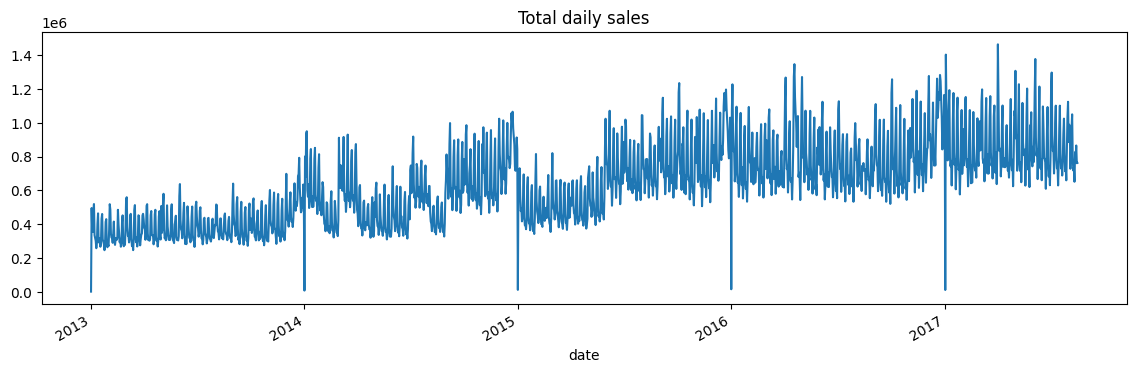

In [4]:
# Aggregate daily sales
daily = train.groupby('date')['sales'].sum()
plt.figure(figsize=(14,4))
daily.plot()
plt.title('Total daily sales')
plt.show()

In [5]:
# 1,782 series (54 stores × 33 families), ~4.5 years

# 31% zero sales — heavy intermittency, common for retail

# Strong upward trend + weekly sawtooth + year-end spikes

# 4 missing dates — worth checking

Missing: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


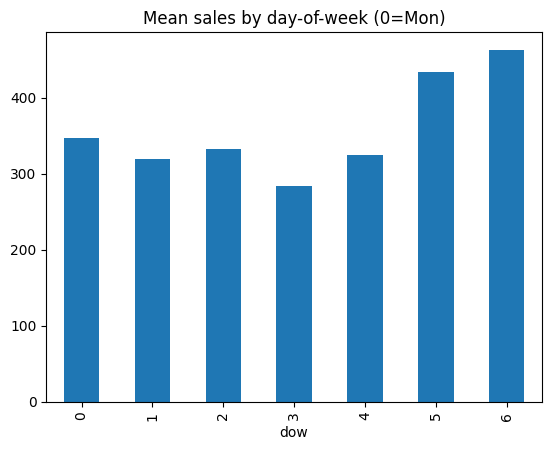

In [6]:
# Missing dates + day-of-week
print("Missing:", sorted(missing.strftime('%Y-%m-%d')))

train['dow'] = train.date.dt.dayofweek
train.groupby('dow')['sales'].mean().plot(kind='bar', title='Mean sales by day-of-week (0=Mon)')
plt.show()

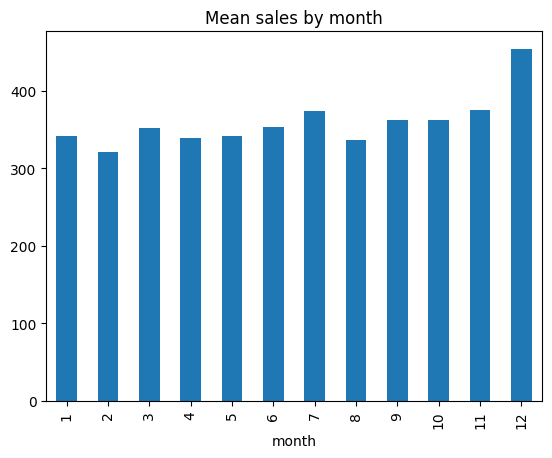

In [7]:
# Monthly seasonality
train['month'] = train.date.dt.month
train.groupby('month')['sales'].mean().plot(kind='bar', title='Mean sales by month')
plt.show()

date
2017-04-01    1.463084e+06
2017-01-02    1.402306e+06
2017-06-04    1.376512e+06
2016-04-18    1.345921e+06
2017-05-01    1.306699e+06
2017-07-02    1.296379e+06
2016-12-23    1.282146e+06
2016-12-04    1.276195e+06
2016-04-17    1.271834e+06
2016-05-01    1.270121e+06
2016-04-03    1.266908e+06
2016-12-18    1.260472e+06
2016-10-02    1.256480e+06
2016-12-24    1.246838e+06
2015-10-04    1.234131e+06
Name: sales, dtype: float64


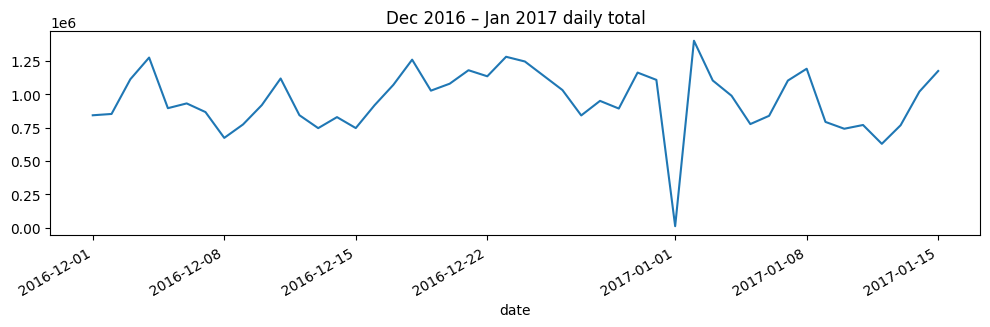

In [8]:
# Year-end spike check
peak_days = daily.nlargest(15)
print(peak_days)

# zoom into Dec 2016
d = daily['2016-12-01':'2017-01-15']
d.plot(figsize=(12,3), title='Dec 2016 – Jan 2017 daily total')
plt.show()

In [9]:
# Are the year-end spikes real or artifacts?
# check a single store+family around Dec 25
mask = (train.store_nbr==1) & (train.family=='GROCERY I') & (train.date.between('2016-12-20','2017-01-05'))
print(train.loc[mask, ['date','sales','onpromotion']].to_string(index=False))

      date  sales  onpromotion
2016-12-20 4080.0          123
2016-12-21 5162.0          116
2016-12-22 5055.0          116
2016-12-23 5386.0          125
2016-12-24 3609.0          103
2016-12-26  904.0           80
2016-12-27 3156.0          101
2016-12-28 2761.0          105
2016-12-29 2573.0          101
2016-12-30 3292.0          103
2016-12-31 2768.0          107
2017-01-01    0.0            0
2017-01-02 1218.0           55
2017-01-03 3507.0           78
2017-01-04 3665.0          109
2017-01-05 3085.0           49


In [10]:
# Clear patterns:

# Closed days: Dec 25 every year + Jan 1 (store 1 shows 0). ~4 missing dates = Dec 25s.

# Weekly: Sat/Sun peak, Wed dip.

# Yearly: Dec peak, Feb low.

# Payday effect: Top days cluster on the 1st and 15th (e.g., 2017-04-01, 2016-12-24→payday shifted, 2015-10-04).

In [11]:
# Time-based split + baselines
# We forecast the last 90 days (2017-05-18 → 2017-08-15) using the rest for training
horizon = 90
cutoff = train.date.max() - pd.Timedelta(days=horizon)
tr = train[train.date <= cutoff]
te = train[train.date > cutoff]
print("cutoff:", cutoff.date(), "| train:", tr.shape, "| test:", te.shape)

cutoff: 2017-05-17 | train: (2840508, 8) | test: (160380, 8)


In [15]:
# Baselines (aggregate daily)
# Build daily total for train/test
# Ensure daily series has every date
# Ensure daily series covers only the training range
# Daily totals
full_idx = pd.date_range(train.date.min(), cutoff, freq='D')
tr_daily = tr.groupby('date')['sales'].sum().reindex(full_idx, fill_value=0)
te_daily = te.groupby('date')['sales'].sum()

# Naive: repeat last observed value
naive = pd.Series(tr_daily.loc[cutoff], index=te_daily.index)

# Seasonal naive (multi-step): last training week, mapped by weekday
last_week = tr_daily.iloc[-7:]
weekday_map = {d: last_week[last_week.index.dayofweek == d].iloc[-1] for d in range(7)}
seasonal_naive = pd.Series([weekday_map[d.dayofweek] for d in te_daily.index], index=te_daily.index)

def metrics(y_true, y_pred, name):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100
    print(f"{name:15s} MAE={mae:>10.0f}  RMSE={rmse:>10.0f}  WAPE={wape:>6.2f}%")

metrics(te_daily, naive, "Naive")
metrics(te_daily, seasonal_naive, "SeasonalNaive")

Naive           MAE=    129318  RMSE=    164712  WAPE= 15.12%
SeasonalNaive   MAE=     93468  RMSE=    130809  WAPE= 10.93%


In [16]:
import pandas as pd
tr = pd.read_pickle('../data/processed/train.pkl')
s = tr[(tr.store_nbr==1) & (tr.family_code==0)].tail(60)
print(s[['date','sales','roll_mean_7','roll_mean_28']].tail(15))
print("\nfamily_code 0 =", pd.read_csv('../data/raw/train.csv').family.astype('category').cat.categories[0])
print("median recent:", s.sales.median(), "| mean recent:", s.sales.mean())


           date  sales  roll_mean_7  roll_mean_28
1219 2017-05-03    5.0     2.857143      4.000000
1220 2017-05-04    3.0     3.285714      4.000000
1221 2017-05-05   12.0     2.571429      3.750000
1222 2017-05-06    4.0     3.857143      3.857143
1223 2017-05-07    3.0     4.142857      3.714286
1224 2017-05-08    5.0     4.142857      3.750000
1225 2017-05-09    2.0     4.857143      3.750000
1226 2017-05-10    2.0     4.857143      3.607143
1227 2017-05-11    4.0     4.428571      3.571429
1228 2017-05-12    4.0     4.571429      3.392857
1229 2017-05-13    2.0     3.428571      3.500000
1230 2017-05-14    2.0     3.142857      3.464286
1231 2017-05-15    9.0     3.000000      3.500000
1232 2017-05-16    3.0     3.571429      3.785714
1233 2017-05-17    2.0     3.714286      3.785714

family_code 0 = AUTOMOTIVE
median recent: 3.0 | mean recent: 4.266666666666667
